# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



In [3]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

In [4]:
dataset_path = '/content/WA_Fn-UseC_-HR-Employee-Attrition.csv'
df = pd.read_csv(dataset_path)
print(df.shape)
df.head(5)

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### Part 1: Chi-Square Test of Independence

#### 1. Research Question
Is an employee's department associated with whether they work overtime?

#### 2. Hypotheses
- **Null hypothesis ($H_0$):** An employee's department and overtime status are independent.
- **Alternative hypothesis ($H_1$):** An employee's department and overtime status are associated.

In [5]:
from scipy.stats import chi2_contingency

# 3. Compute contingency table
contingency_table = pd.crosstab(df['Department'], df['OverTime'])
print("Contingency Table (Counts):")
display(contingency_table)

# 4. Execute Chi-Square Test of Independence
chi2_stat, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"p-value: {p_val:.4e}")

alpha = 0.05
if p_val < alpha:
    print(f"\nSince p-value < {alpha}, we REJECT the null hypothesis (H0). There is a statistically significant association between Department and OverTime status.")
else:
    print(f"\nSince p-value >= {alpha}, we FAIL TO REJECT the null hypothesis (H0). There is no significant association between Department and OverTime status.")

Contingency Table (Counts):


OverTime,No,Yes
Department,,
Human Resources,46,17
Research & Development,690,271
Sales,318,128


Chi-Square Statistic: 0.0936
Degrees of Freedom: 2
p-value: 9.5428e-01

Since p-value >= 0.05, we FAIL TO REJECT the null hypothesis (H0). There is no significant association between Department and OverTime status.


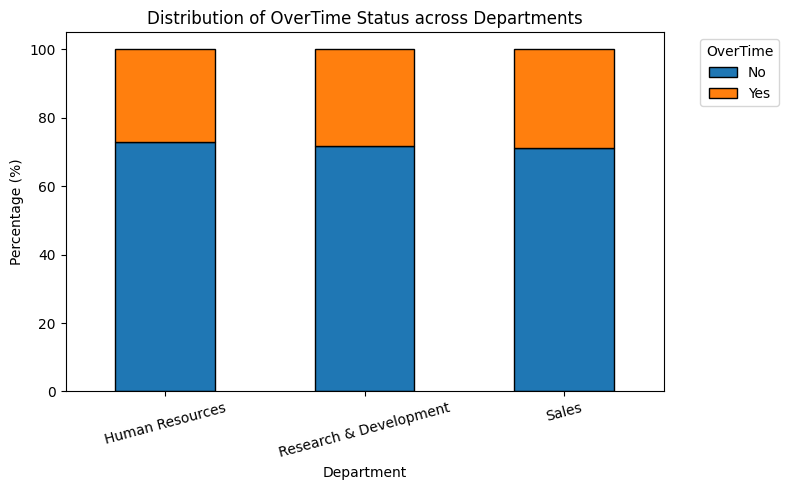

In [6]:
# 5. Create a normalized (proportional) stacked bar chart for better visualization of proportions
contingency_prop = pd.crosstab(df['Department'], df['OverTime'], normalize='index') * 100

plt.figure(figsize=(8, 5))
contingency_prop.plot(kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'], edgecolor='black', ax=plt.gca())
plt.title('Distribution of OverTime Status across Departments')
plt.xlabel('Department')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=15)
plt.legend(title='OverTime', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### 6. HR Interpretation
The p-value was about 0.9543, which is greater than 0.05, so I failed to reject the null hypothesis. There was not enough evidence to say that an employee's department was associated with whether they worked overtime. For an HR manager, the chart shows similar overtime rates across the departments, but this does not mean every employee has the same workload.

### Part 2: One-Way ANOVA

#### 1. Research Question
Does average monthly income differ between Human Resources, Research & Development, and Sales?

#### 2. Hypotheses
- **Null hypothesis ($H_0$):** All three departments have the same population mean monthly income.
  $$\mu_{\mathrm{HR}} = \mu_{\mathrm{R\&D}} = \mu_{\mathrm{Sales}}$$
- **Alternative hypothesis ($H_1$):** At least one department has a different population mean monthly income.

In [7]:
from scipy.stats import f_oneway

# 3. Group the continuous numerical data by the categorical categories
hr_income = df[df['Department'] == 'Human Resources']['MonthlyIncome']
rd_income = df[df['Department'] == 'Research & Development']['MonthlyIncome']
sales_income = df[df['Department'] == 'Sales']['MonthlyIncome']

# Execute One-Way ANOVA
f_stat, p_val_anova = f_oneway(hr_income, rd_income, sales_income)

print(f"F-Statistic: {f_stat:.4f}")
print(f"p-value: {p_val_anova:.4e}")

alpha = 0.05
if p_val_anova < alpha:
    print(f"\nSince p-value < {alpha}, we REJECT the null hypothesis (H0). There is a statistically significant difference in mean MonthlyIncome across the different Departments.")
else:
    print(f"\nSince p-value >= {alpha}, we FAIL TO REJECT the null hypothesis (H0). There is no statistically significant difference in mean MonthlyIncome across the different Departments.")

F-Statistic: 3.2018
p-value: 4.0974e-02

Since p-value < 0.05, we REJECT the null hypothesis (H0). There is a statistically significant difference in mean MonthlyIncome across the different Departments.


/tmp/ipykernel_3249/3701586252.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Department', y='MonthlyIncome', palette='Set2')


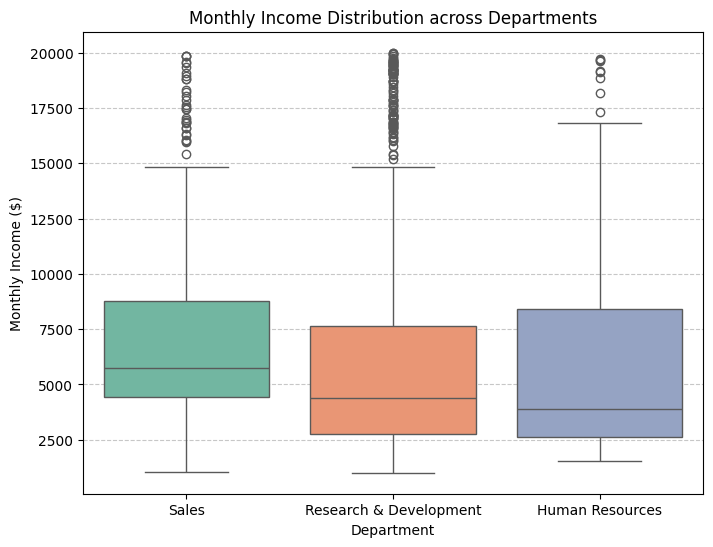

In [8]:
# 4. Generate a boxplot displaying MonthlyIncome across different Departments
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Department', y='MonthlyIncome', palette='Set2')
plt.title('Monthly Income Distribution across Departments')
plt.xlabel('Department')
plt.ylabel('Monthly Income ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### 5. Statistical Conclusions & HR Interpretation
The ANOVA test gave an F-statistic of 3.2018 and a p-value of about 0.04097, so I rejected the null hypothesis because the p-value was below 0.05. This suggests that average monthly income differs between at least two departments, although the test does not tell us exactly which ones. Sales appears to have the highest median income in the boxplot, so an HR manager could look into the differences while considering each department's job roles and responsibilities.

## Part 3: Assessing Decision Errors in HR Policy

For this section, I chose the ANOVA test comparing average monthly income across departments.

#### 1. Type I Error (False Positive)
A Type I error would happen if I rejected the null hypothesis and concluded that average monthly income differed between departments when the population means were actually the same. HR might spend time and money investigating a difference that was not really there.

#### 2. Type II Error (False Negative)
A Type II error would happen if I failed to reject the null hypothesis even though at least one department actually had a different population mean monthly income. HR could overlook a real pay difference and miss a chance to investigate why it exists. A difference alone would not prove unfair pay because departments can have different roles, experience levels, and responsibilities.

#### 3. Which Error Is More Concerning?
I think a Type II error would be more concerning because a real pay difference could go unnoticed. If that difference turned out to involve unfair pay, leaving it unaddressed could make employees unhappy and cause some to leave. A Type I error could also waste money and time, but I would be more concerned about missing a real issue that affects employees.